## Segment Tree(セグメントツリー)

区間クエリや更新が高速に行える木構造について解説します。

### セグ木について

セグメントツリーは、配列に対する区間クエリと一点更新をO(log(n))で行うことができる木構造です。  
具体的には、ある区間の最小・最大値,和など、結合法則が成り立つ演算なら何でも取り扱うことができます。

|操作|オーダー|
| ------------ | ---------------- |
|区間クエリ|O(log(N))|
|一点更新|O(log(N))|
|区間更新(M個)|通常O(Mlog(N)),後述の遅延評価セグメント木ではO(log(N))|


下図は A = [3,1,4,1,5,9,2,6]のときの`最小値`についての値を持つセグ木の例です。  
サイズは2Nとなっており、上に行くにつれてより大きな区間の最小値を持つようになっています。

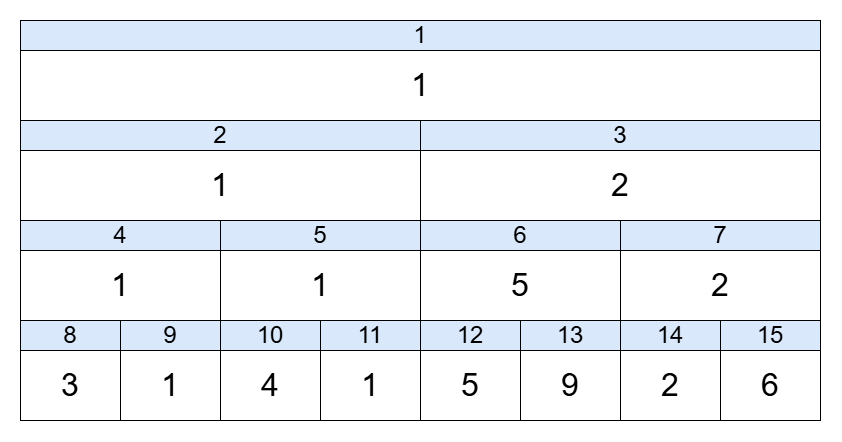

### 区間クエリの計算

上図の区間[l:r)における最小値を求めることを考えます。  
今回は、l=2,r=7,N=8,A[l:r]=[4,1,5,9,2],seg = セグ木とします。  
また、暫定の最小値をansに保存するため、十分に大きな値で初期化します。  

L = l+N = 10,R = r+N = 15 とし、それぞれの葉にアクセスできるようにします。  

L=10,R=15,ans = inf  
Lは偶数なので、L = L//2 = 5として親に移動。  
Rは奇数で範囲外のため、R=R-1=14とし、ans = min(ans,seg[14]) = 2とし、R = R//2 = 7  

L=5,R=7,ans = 2  
Lは奇数で親は使えないので、ans=min(ans,seg[5])=1とし、L=L+1=6,L=L//2 = 3  
Rは奇数で範囲外のため、R=R-1=6とし、ans =min(ans,seg[6])=1とし、 R=R//2 = 3  

L=R=3のため操作を終了。ans = 1


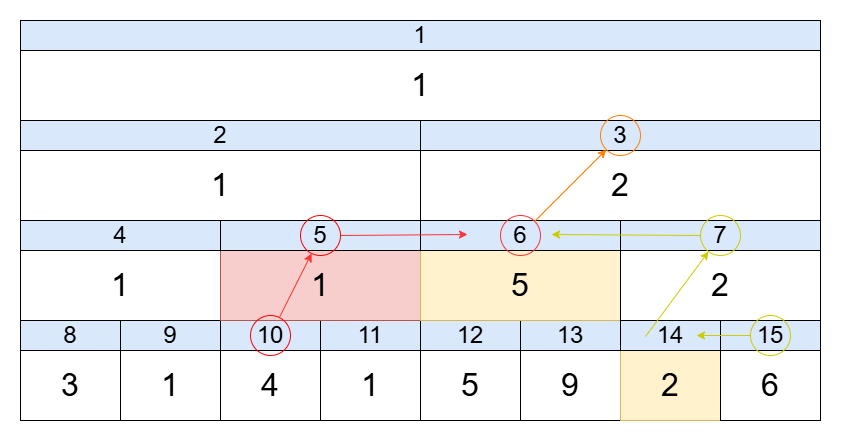

### 一点更新

一点更新は区間クエリとはことなり、比較的処理が簡単で直感的です。  
A[1]の値を１から２に変更したいとします。
まずseg[9]=2とします。  
次に親であるseg[4]を、２つの子の値を用いて演算し更新します。seg[4] = min(seg[8],seg[9])  
同様にseg[2],seg[1]を更新することで一点更新の操作はlog(n)で完了することがわかります。  

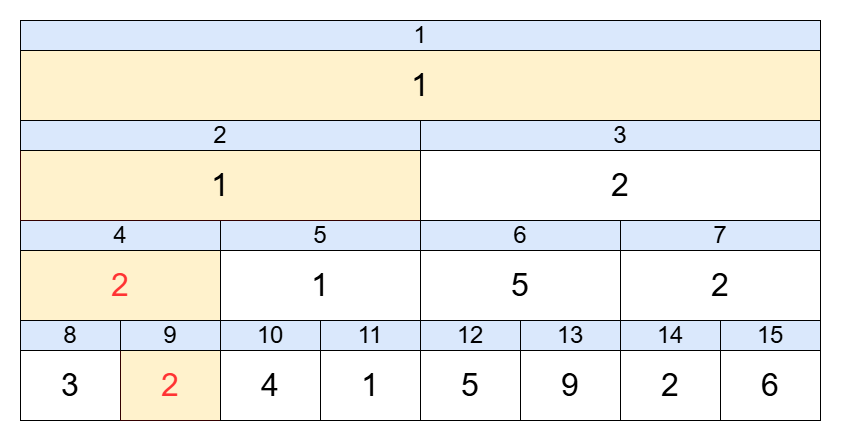

### ライブラリでの実装

AtCoder Library(ACL)にはセグ木のライブラリが存在します。  

In [8]:
from atcoder.segtree import SegTree

def op(x, y): # 演算関数の定義 (min, max, xor, 和など)
    return min(x, y)
e = float('inf') # 単位元の定義
a = [3,1,4,1,5,9,2,6] # 対象データを適宜設定

st = SegTree(op, e, a) # 初期化: SegTree(演算関数, 単位元, 配列)

print(st.prod(0, 3))  # 区間取得: prod(l, r) [0, 3) の最小値 -> 1

st.set(1, 2)         # 一点更新: a[1] を 2 に変更
print(st.prod(0, 3))  # [0, 3) の最小値
print(st.all_prod()) # 配列全体の取得

1
2
1


#### 操作一覧

|操作|操作内容|計算量|
|---|---|---|
|SegTree.prod(l,r)|[0, 3) の演算結果|$O(log(N))$|
|SegTree.all_prod()|全体の演算結果|$O(1)$|
|SegTree.set(i,x)|元の配列Aの$A[i]$をxに変更|$O(log(N))$|

prodは代数学における結合法則が成り立つ二項演算( $a \circ b$ )の結果を広く呼ぶ「積」(product)から来ています。  
掛け算の積ではないです。